
# **NeuDetect**
Brain Tumor Detection using Deep Learning and Explainable AI

###Model:
    ResNet50 Transfer Learning

###Dataset:
    Brain Tumor MRI Dataset
    (Masoud Nickparvar - Kaggle)

###Classes:
    - Glioma
    - Meningioma
    - No Tumor
    - Pituitary

###Framework:
    TensorFlow / Keras

###Author:
    Mahnoor


In [53]:
# Standard Libraries

import os
import cv2
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# TensorFlow

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D
)

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from tensorflow.keras.metrics import (
    Precision,
    Recall,
    AUC
)

# Scikit-learn

from sklearn.utils import class_weight

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Settings

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

print("=" * 55)
print("NeuDetect Environment Loaded Successfully")
print("TensorFlow Version :", tf.__version__)
print("=" * 55)

NeuDetect Environment Loaded Successfully
TensorFlow Version : 2.20.0



# Mount Google Drive


In [2]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/NeuDetect"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("=" * 55)
print("Google Drive Mounted Successfully")
print("Project Directory:")
print(PROJECT_DIR)
print("=" * 55)

Mounted at /content/drive
Google Drive Mounted Successfully
Project Directory:
/content/drive/MyDrive/NeuDetect


# Download Brain MRI Dataset

In [3]:
# Download Brain MRI Dataset

import kagglehub

print("Downloading dataset...")

dataset_path = kagglehub.dataset_download(
    "masoudnickparvar/brain-tumor-mri-dataset"
)

print("\nDataset downloaded successfully!")

print("\nDataset Location:")
print(dataset_path)

print("\nContents:")
print(os.listdir(dataset_path))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.

Dataset downloaded successfully!

Dataset Location:
/kaggle/input/brain-tumor-mri-dataset

Contents:
['Training', 'Testing']


# Dataset Paths & Verification

In [4]:
# Dataset Paths & Verification

train_path = os.path.join(dataset_path, "Training")
test_path = os.path.join(dataset_path, "Testing")

print("=" * 60)
print("Dataset Verification")
print("=" * 60)

print(f"\nTraining Path:\n{train_path}")
print(f"\nTesting Path:\n{test_path}")

# Verify folders exist
assert os.path.exists(train_path), "Training folder not found!"
assert os.path.exists(test_path), "Testing folder not found!"

print("\nTraining Classes:")
train_classes = sorted(os.listdir(train_path))

for cls in train_classes:
    total = len(os.listdir(os.path.join(train_path, cls)))
    print(f"  {cls:<12} : {total} images")

print("\nTesting Classes:")
test_classes = sorted(os.listdir(test_path))

for cls in test_classes:
    total = len(os.listdir(os.path.join(test_path, cls)))
    print(f"  {cls:<12} : {total} images")

print("\nDataset verified successfully.")
print("=" * 60)

Dataset Verification

Training Path:
/kaggle/input/brain-tumor-mri-dataset/Training

Testing Path:
/kaggle/input/brain-tumor-mri-dataset/Testing

Training Classes:
  glioma       : 1400 images
  meningioma   : 1400 images
  notumor      : 1400 images
  pituitary    : 1400 images

Testing Classes:
  glioma       : 400 images
  meningioma   : 400 images
  notumor      : 400 images
  pituitary    : 400 images

Dataset verified successfully.


# Data Generators

In [5]:

# Image Data Generators

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Training Generator

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.20,
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    fill_mode="nearest"
)

# Validation Generator

validation_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.20
)

# Testing Generator

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Create Data Generators

train_gen = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=SEED
)

val_gen = validation_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("\n" + "=" * 60)
print("Data Generators Created Successfully")
print("=" * 60)

print(f"Training Images   : {train_gen.samples}")
print(f"Validation Images : {val_gen.samples}")
print(f"Testing Images    : {test_gen.samples}")

print("\nClass Mapping:")
print(train_gen.class_indices)

Found 4480 images belonging to 4 classes.
Found 1120 images belonging to 4 classes.
Found 1600 images belonging to 4 classes.

Data Generators Created Successfully
Training Images   : 4480
Validation Images : 1120
Testing Images    : 1600

Class Mapping:
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


# Visual Data Verification

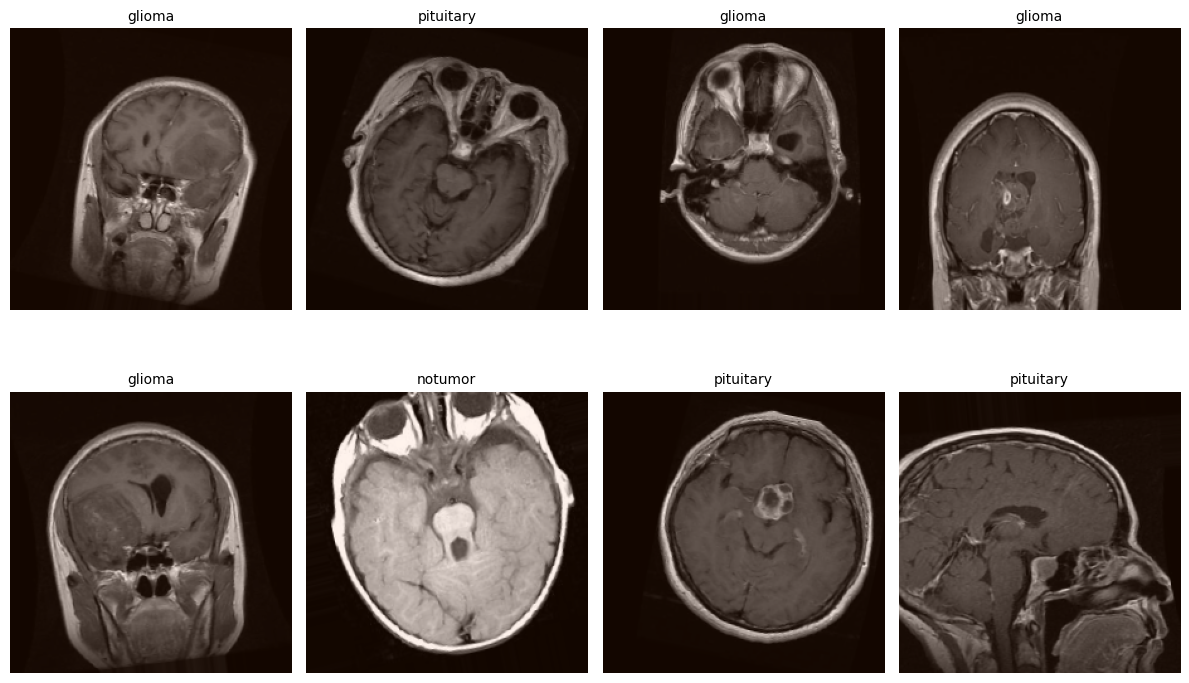

In [6]:

# Visualize Sample MRI Images


images, labels = next(train_gen)

class_names = list(train_gen.class_indices.keys())

plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    # Convert preprocessing back approximately for display
    img = images[i]

    img = img - img.min()
    img = img / img.max()

    plt.imshow(img)

    label_index = np.argmax(labels[i])

    plt.title(
        class_names[label_index],
        fontsize=10
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

# 6.1: Check Label Mapping With File Paths

In [7]:

# Verify Image Labels


import random

# Pick random indexes
random_indexes = random.sample(range(len(train_gen.filepaths)), 5)

print("=" * 60)
print("Random Image Label Verification")
print("=" * 60)

for idx in random_indexes:

    filepath = train_gen.filepaths[idx]

    # Extract folder name (actual class)
    actual_folder = os.path.basename(
        os.path.dirname(filepath)
    )

    # Generator label
    label_index = train_gen.classes[idx]

    generator_label = class_names[label_index]

    print("\nImage:")
    print(filepath)

    print("Folder Label :", actual_folder)
    print("Generator Label :", generator_label)

    if actual_folder == generator_label:
        print("✅ MATCH")
    else:
        print("❌ MISMATCH")

Random Image Label Verification

Image:
/kaggle/input/brain-tumor-mri-dataset/Training/glioma/Tr-gl_811.jpg
Folder Label : glioma
Generator Label : glioma
✅ MATCH

Image:
/kaggle/input/brain-tumor-mri-dataset/Training/glioma/Tr-gl_174.jpg
Folder Label : glioma
Generator Label : glioma
✅ MATCH

Image:
/kaggle/input/brain-tumor-mri-dataset/Training/notumor/Tr-no_1262.jpg
Folder Label : notumor
Generator Label : notumor
✅ MATCH

Image:
/kaggle/input/brain-tumor-mri-dataset/Training/meningioma/Tr-me_789.jpg
Folder Label : meningioma
Generator Label : meningioma
✅ MATCH

Image:
/kaggle/input/brain-tumor-mri-dataset/Training/meningioma/Tr-me_628.jpg
Folder Label : meningioma
Generator Label : meningioma
✅ MATCH


# Class Distribution & Class Weights

In [8]:

# Class Distribution & Class Weights


from sklearn.utils import class_weight

# Get training labels
labels = train_gen.classes

# Calculate class weights
weights = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = dict(
    enumerate(weights)
)

print("=" * 60)
print("Class Distribution")
print("=" * 60)

for class_name, index in train_gen.class_indices.items():
    count = np.sum(labels == index)
    print(f"{class_name:<12}: {count} images")

print("\nClass Weights:")
print(class_weights)

print("=" * 60)

Class Distribution
glioma      : 1120 images
meningioma  : 1120 images
notumor     : 1120 images
pituitary   : 1120 images

Class Weights:
{0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0)}


# ResNet50 Transfer Learning Model
# Phase 1: Feature Extraction

In [9]:

# ResNet50 Transfer Learning Model
# Phase 1: Feature Extraction


from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import Precision, Recall, AUC


# Load ResNet50 without ImageNet classifier
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)


# Freeze pretrained layers initially
base_model.trainable = False


# Custom classification head
x = base_model.output

x = GlobalAveragePooling2D()(x)

x = Dense(
    256,
    activation="relu"
)(x)

x = Dropout(
    0.5
)(x)


output = Dense(
    4,
    activation="softmax"
)(x)


model = Model(
    inputs=base_model.input,
    outputs=output
)


# Compile Phase 1

model.compile(
    optimizer=Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy",
        Precision(name="precision"),
        Recall(name="recall"),
        AUC(name="auc")
    ]
)


print("=" * 60)
print("ResNet50 Model Created Successfully")
print("=" * 60)

model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 Model Created Successfully


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 525,572 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

# CALLBACKS

In [10]:

# CALLBACKS


from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

checkpoint_path = os.path.join(
    PROJECT_DIR,
    "best_resnet50_model.keras"
)

callbacks = [
    # 1. Stop training when validation loss stops improving
    EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    # 2. Drop learning rate when validation loss plateaus
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    # 3. Save the model state matching the lowest validation loss
    ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    )
]

print("=" * 60)
print("Callbacks Configured Successfully (Aligned on val_loss)")
print("=" * 60)

Callbacks Configured Successfully (Aligned on val_loss)


# PHASE 1 TRAINING
# Feature Extraction

In [11]:

# PHASE 1 TRAINING
# Feature Extraction

print("=" * 60)
print("Starting Phase 1 Training")
print("Training only the classification head")
print("=" * 60)


history_phase1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


print("=" * 60)
print("Phase 1 Training Completed")
print("=" * 60)

Starting Phase 1 Training
Training only the classification head
Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 710ms/step - accuracy: 0.6649 - auc: 0.8579 - loss: 1.0422 - precision: 0.6991 - recall: 0.6190
Epoch 1: val_loss improved from None to 0.35322, saving model to /content/drive/MyDrive/NeuDetect/best_resnet50_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/NeuDetect/best_resnet50_model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 148s 887ms/step - accuracy: 0.7580 - auc: 0.9273 - loss: 0.6694 - precision: 0.7950 - recall: 0.7161 - val_accuracy: 0.8562 - val_auc: 0.9775 - val_loss: 0.3532 - val_precision: 0.8653 - val_recall: 0.8491 - learning_rate: 0.0010
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 698ms/step - accuracy: 0.8392 - auc: 0.9690 - loss: 0.4151 - precision: 0.8571 - recall: 0.8121
Epoch 2: val_loss did not improve from 0.35322
140/140 ━━━━━━━━━━━━━━━━━━━━ 108s 730ms/step - accuracy: 0.8429 - auc: 0.9692 - loss: 0.4142 - precision: 0.8636 - recall: 0.8165 - va

# PHASE 1 Training History Visualization

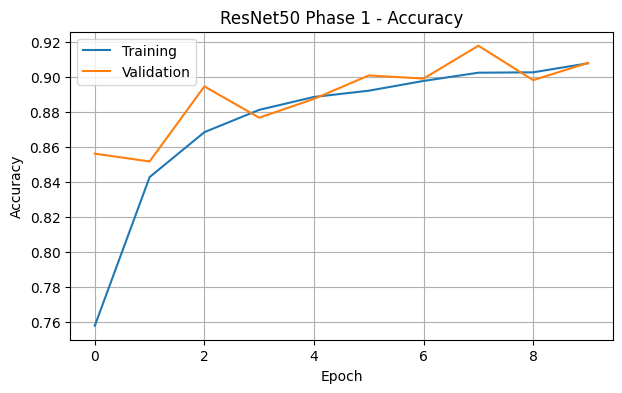

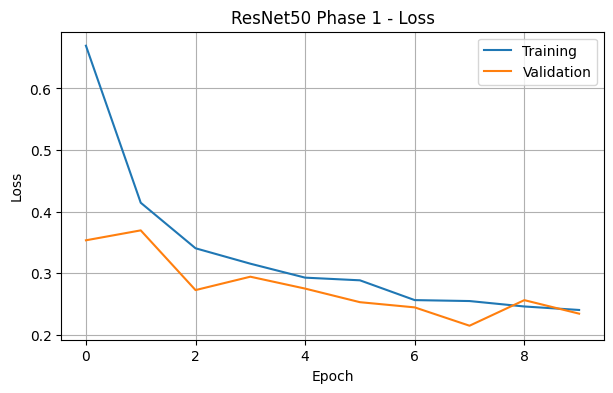

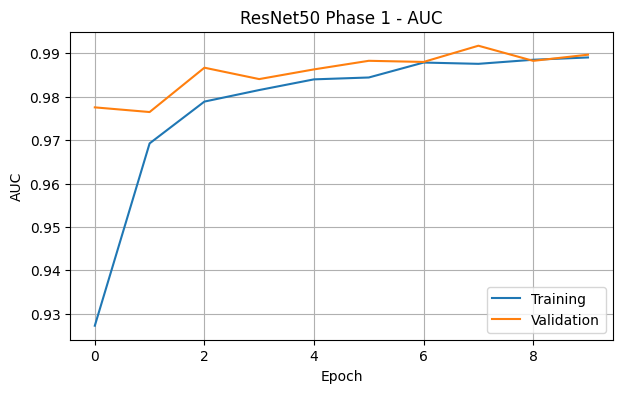

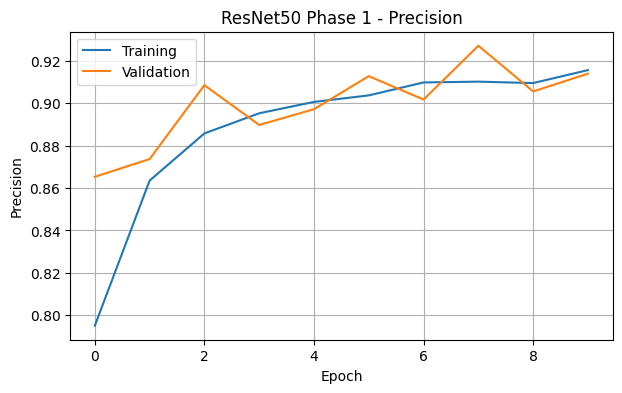

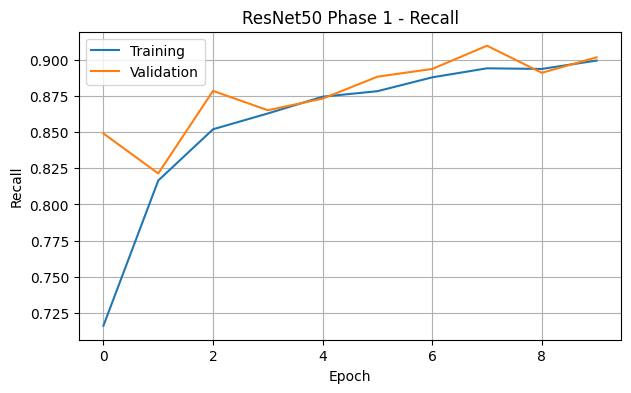

In [12]:

# PHASE 1 TRAINING HISTORY VISUALIZATION

import matplotlib.pyplot as plt


def plot_history(history):

    metrics = [
        ("accuracy", "Accuracy"),
        ("loss", "Loss"),
        ("auc", "AUC"),
        ("precision", "Precision"),
        ("recall", "Recall")
    ]


    for metric, title in metrics:

        plt.figure(figsize=(7,4))

        plt.plot(
            history.history[metric],
            label="Training"
        )

        plt.plot(
            history.history["val_" + metric],
            label="Validation"
        )

        plt.title(
            f"ResNet50 Phase 1 - {title}"
        )

        plt.xlabel("Epoch")
        plt.ylabel(title)

        plt.legend()
        plt.grid(True)

        plt.show()



plot_history(history_phase1)

# PHASE 2: FINE-TUNING PREPARATION

In [13]:

# PHASE 2: FINE-TUNING PREPARATION (IMPROVED)

from tensorflow.keras.layers import BatchNormalization

print("=" * 60)
print("Preparing Model For Fine-Tuning")
print("=" * 60)


# Unfreeze base model
base_model.trainable = True


# Freeze all except last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False


# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False


# Check trainable layers

trainable_count = 0
frozen_count = 0

for layer in base_model.layers:

    if layer.trainable:
        trainable_count += 1
    else:
        frozen_count += 1


print("Trainable layers :", trainable_count)
print("Frozen layers    :", frozen_count)


print("=" * 60)
print("Fine-Tuning Preparation Completed")
print("=" * 60)

Preparing Model For Fine-Tuning
Trainable layers : 21
Frozen layers    : 154
Fine-Tuning Preparation Completed


# PHASE 2: MODEL RECOMPILATION

In [14]:

# PHASE 2: MODEL RECOMPILATION

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import Precision, Recall, AUC


model.compile(

    optimizer=Adam(
        learning_rate=1e-5
    ),

    loss="categorical_crossentropy",

    metrics=[
        "accuracy",
        Precision(name="precision"),
        Recall(name="recall"),
        AUC(name="auc")
    ]
)


print("=" * 60)
print("Model Recompiled For Fine-Tuning")
print("=" * 60)


model.summary()


Model Recompiled For Fine-Tuning


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 14,954,244 (57.05 MB)

 Non-trainable params: 9,159,040 (34.94 MB)

# Phase 2 Training

In [15]:

# PHASE 2: FINE-TUNING TRAINING
fine_tune_epochs = 10

total_epochs = len(history_phase1.history["loss"]) + fine_tune_epochs

history_fine = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=total_epochs,
    initial_epoch=len(history_phase1.history["loss"]),
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


Epoch 11/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 493ms/step - accuracy: 0.9064 - auc: 0.9892 - loss: 0.2399 - precision: 0.9153 - recall: 0.8980
Epoch 11: val_loss improved from 0.21442 to 0.18649, saving model to /content/drive/MyDrive/NeuDetect/best_resnet50_model.keras

Epoch 11: finished saving model to /content/drive/MyDrive/NeuDetect/best_resnet50_model.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 101s 589ms/step - accuracy: 0.9165 - auc: 0.9911 - loss: 0.2179 - precision: 0.9248 - recall: 0.9080 - val_accuracy: 0.9259 - val_auc: 0.9931 - val_loss: 0.1865 - val_precision: 0.9297 - val_recall: 0.9205 - learning_rate: 1.0000e-05
Epoch 12/20
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 560ms/step - accuracy: 0.9350 - auc: 0.9941 - loss: 0.1728 - precision: 0.9434 - recall: 0.9316
Epoch 12: val_loss improved from 0.18649 to 0.18457, saving model to /content/drive/MyDrive/NeuDetect/best_resnet50_model.keras

Epoch 12: finished saving model to /content/drive/MyDrive/NeuDetect/best_resnet50_model.keras
140/140 ━━━

Evaluating Model on Test Dataset
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 211ms/step - accuracy: 0.9131 - auc: 0.9719 - loss: 0.5552 - precision: 0.9142 - recall: 0.9125

Test Results:
  Loss        : 0.5552
  Compile_metrics: 0.9131
50/50 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step

Classification Report
              precision    recall  f1-score   support

      glioma     0.9804    0.7500    0.8499       400
  meningioma     0.8192    0.9175    0.8656       400
     notumor     0.9408    0.9925    0.9659       400
   pituitary     0.9363    0.9925    0.9636       400

    accuracy                         0.9131      1600
   macro avg     0.9192    0.9131    0.9112      1600
weighted avg     0.9192    0.9131    0.9112      1600



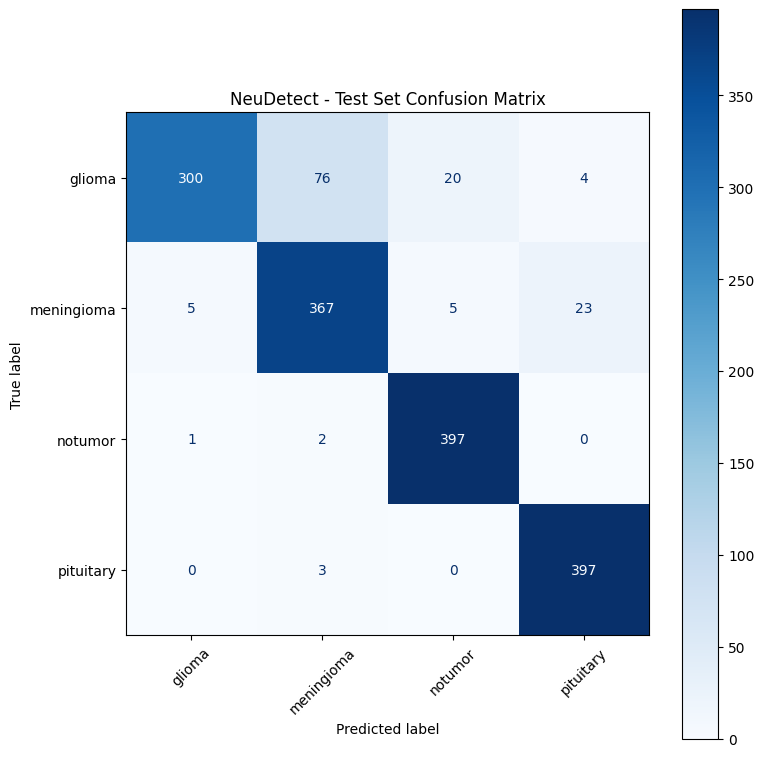

In [16]:
# EVALUATION & TEST SET PREDICTIONS

print("=" * 60)
print("Evaluating Model on Test Dataset")
print("=" * 60)

# Evaluate model metrics on test generator
test_eval = model.evaluate(test_gen, verbose=1)

print("\nTest Results:")
for metric_name, value in zip(model.metrics_names, test_eval):
    print(f"  {metric_name.capitalize():<12}: {value:.4f}")

# Reset test generator to ensure correct sample order
test_gen.reset()

# Predict probabilities and get class indices
y_pred_probs = model.predict(test_gen, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_gen.classes

class_labels = list(test_gen.class_indices.keys())

print("\n" + "=" * 60)
print("Classification Report")
print("=" * 60)
print(
    classification_report(
        y_true, y_pred, target_names=class_labels, digits=4
    )
)

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=class_labels
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title("NeuDetect - Test Set Confusion Matrix")
plt.tight_layout()
plt.show()


# 11. Explainable AI (Grad-CAM)

In [17]:
# ==========================================================
# SECTION 11
# Explainable AI (Grad-CAM)
# ==========================================================

import tensorflow as tf
import cv2
import numpy as np

Step 11.2: Create an output folder

This lets us save Grad-CAM images. Later the backend can send these images to the frontend.

In [51]:
GRADCAM_DIR = os.path.join(PROJECT_DIR, "gradcam_outputs")

os.makedirs(GRADCAM_DIR, exist_ok=True)

print("Grad-CAM Output Folder:")
print(GRADCAM_DIR)

Grad-CAM Output Folder:
/content/drive/MyDrive/NeuDetect/gradcam_outputs


Step 11.3: Create the Grad-CAM function

In [19]:
def generate_gradcam(
    model,
    img_array,
    last_conv_layer_name="conv5_block3_out"
):
    """
    Generates a Grad-CAM heatmap.

    Parameters
    ----------
    model : Trained Keras model

    img_array : Preprocessed image
                Shape (1,224,224,3)

    last_conv_layer_name : Final convolution layer

    Returns
    -------
    heatmap : numpy array
    """

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(img_array)

        predicted_class = tf.argmax(predictions[0])

        loss = predictions[:, predicted_class]

    gradients = tape.gradient(loss, conv_outputs)

    pooled_gradients = tf.reduce_mean(
        gradients,
        axis=(0,1,2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        pooled_gradients * conv_outputs,
        axis=-1
    )

    heatmap = tf.maximum(heatmap,0)

    max_value = tf.reduce_max(heatmap)

    if max_value == 0:
        return np.zeros_like(heatmap)

    heatmap /= max_value

    return heatmap.numpy()

Step 11.4: Create the overlay function

In [20]:
def overlay_gradcam(
    original_image,
    heatmap,
    alpha=0.4
):
    """
    Overlay heatmap onto image.

    original_image:
        RGB image
        values between 0 and 1
    """

    heatmap = cv2.resize(
        heatmap,
        (
            original_image.shape[1],
            original_image.shape[0]
        )
    )

    heatmap = np.uint8(255 * heatmap)

    heatmap = cv2.applyColorMap(
        heatmap,
        cv2.COLORMAP_JET
    )

    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        np.uint8(original_image*255),
        1-alpha,
        heatmap,
        alpha,
        0
    )

    return overlay

Step 11.5: Test the Grad-CAM

In [21]:
test_gen.reset()

images, labels = next(test_gen)

sample_image = images[0]

sample_batch = np.expand_dims(
    sample_image,
    axis=0
)

heatmap = generate_gradcam(
    model,
    sample_batch
)

Step 11.6: Create the visualization

In [22]:
def show_gradcam(
    image,
    heatmap,
    title="Grad-CAM"
):

    image_display = image.copy()

    image_display -= image_display.min()

    max_value = image_display.max()
    if max_value != 0:
        image_display /= max_value

    overlay = overlay_gradcam(
        image_display,
        heatmap
    )

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)

    plt.imshow(image_display)

    plt.title("Original MRI")

    plt.axis("off")


    plt.subplot(1,2,2)

    plt.imshow(overlay)

    plt.title(title)

    plt.axis("off")

    plt.show()

    return image_display, overlay


Step 11.7: Display the result

In [54]:
display_image, overlay = show_gradcam(
    sample_image,
    heatmap
)

AttributeError: 'str' object has no attribute 'copy'

Save the Grad-CAM output

In [24]:
from datetime import datetime


timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)


save_path = os.path.join(
    GRADCAM_DIR,
    f"gradcam_{timestamp}.png"
)


cv2.imwrite(
    save_path,
    cv2.cvtColor(
        overlay,
        cv2.COLOR_RGB2BGR
    )
)


print("Saved Grad-CAM:")
print(save_path)

Saved Grad-CAM:
/content/drive/MyDrive/NeuDetect/gradcam_outputs/gradcam_20260801_072315.png


# 12. Production MRI Prediction Engine

Step 1: Create prediction output folder

In [25]:
# SECTION 12
# MRI Prediction Engine

PREDICTION_DIR = os.path.join(
    PROJECT_DIR,
    "prediction_outputs"
)

os.makedirs(
    PREDICTION_DIR,
    exist_ok=True
)

print("Prediction Output Folder:")
print(PREDICTION_DIR)

Prediction Output Folder:
/content/drive/MyDrive/NeuDetect/prediction_outputs


Step 2: Get class names

In [26]:
class_names = list(
    train_gen.class_indices.keys()
)

print("Classes:")
print(class_names)

Classes:
['glioma', 'meningioma', 'notumor', 'pituitary']


Step 3: Create the main prediction function

In [27]:
def predict_mri(
    image_path,
    model,
    class_names
):
    """
    Complete MRI analysis pipeline.

    Input:
        image_path : MRI image location

    Output:
        prediction result dictionary
    """

    # -----------------------------
    # 1. Load MRI image
    # -----------------------------

    img = tf.keras.preprocessing.image.load_img(
        image_path,
        target_size=(224,224)
    )


    img_array = tf.keras.preprocessing.image.img_to_array(
        img
    )


    original_image = img_array / 255.0


    # -----------------------------
    # 2. Preprocess for ResNet50
    # -----------------------------

    processed_image = preprocess_input(
        np.expand_dims(
            img_array.copy(),
            axis=0
        )
    )


    # -----------------------------
    # 3. Prediction
    # -----------------------------

    predictions = model.predict(
        processed_image,
        verbose=0
    )


    predicted_index = np.argmax(
        predictions[0]
    )


    predicted_class = class_names[
        predicted_index
    ]


    confidence = float(
        predictions[0][predicted_index] * 100
    )


    # -----------------------------
    # 4. Probability Dictionary
    # -----------------------------

    probabilities = {}

    for i, name in enumerate(class_names):

        probabilities[name] = round(
            float(predictions[0][i] * 100),
            2
        )


    # -----------------------------
    # 5. Generate Grad-CAM
    # -----------------------------

    heatmap = generate_gradcam(
        model,
        processed_image
    )


    overlay = overlay_gradcam(
        original_image,
        heatmap
    )


    # -----------------------------
    # 6. Save Grad-CAM
    # -----------------------------

    filename = (
        "prediction_gradcam.png"
    )


    gradcam_path = os.path.join(
        PREDICTION_DIR,
        filename
    )


    cv2.imwrite(
        gradcam_path,
        cv2.cvtColor(
            overlay,
            cv2.COLOR_RGB2BGR
        )
    )


    # -----------------------------
    # 7. Final Result
    # -----------------------------

    result = {

        "prediction": predicted_class,

        "confidence": round(
            confidence,
            2
        ),

        "probabilities": probabilities,

        "gradcam_path": gradcam_path

    }


    return result

Step 4: Test with one MRI

In [28]:
sample_path = test_gen.filepaths[0]


result = predict_mri(
    sample_path,
    model,
    class_names
)


print(result)

{'prediction': 'notumor', 'confidence': 49.76, 'probabilities': {'glioma': 0.49, 'meningioma': 46.78, 'notumor': 49.76, 'pituitary': 2.97}, 'gradcam_path': '/content/drive/MyDrive/NeuDetect/prediction_outputs/prediction_gradcam.png'}


# 13. Model Saving & Metadata

Step 1: Create folders

In [29]:
# SECTION 13
# Model Saving & Metadata

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

METADATA_DIR = os.path.join(
    PROJECT_DIR,
    "metadata"
)


os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

os.makedirs(
    METADATA_DIR,
    exist_ok=True)


print("Model Folder:")
print(MODEL_DIR)

print("\nMetadata Folder:")
print(METADATA_DIR)

Model Folder:
/content/drive/MyDrive/NeuDetect/models

Metadata Folder:
/content/drive/MyDrive/NeuDetect/metadata


Step 2: Save trained model

In [30]:
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "NeuDetect_ResNet50.keras"
)


model.save(
    MODEL_PATH
)


print("Model saved successfully:")
print(MODEL_PATH)

Model saved successfully:
/content/drive/MyDrive/NeuDetect/models/NeuDetect_ResNet50.keras


Step 3: Save class names

In [31]:
import json


CLASS_PATH = os.path.join(
    METADATA_DIR,
    "class_names.json"
)


with open(
    CLASS_PATH,
    "w"
) as file:

    json.dump(
        class_names,
        file,
        indent=4
    )


print("Class names saved:")
print(CLASS_PATH)

Class names saved:
/content/drive/MyDrive/NeuDetect/metadata/class_names.json


Step 4: Save training configuration

In [32]:
training_config = {

    "model": "ResNet50",

    "task": "Brain Tumor Classification",

    "classes": class_names,

    "image_size": "224x224",

    "dataset":
    "Masoud Nickparvar Brain Tumor MRI Dataset",

    "optimizer":
    "Adam",

    "loss":
    "categorical_crossentropy",

    "explainability":
    "Grad-CAM",

    "framework":
    "TensorFlow Keras"

}


CONFIG_PATH = os.path.join(
    METADATA_DIR,
    "training_config.json"
)


with open(
    CONFIG_PATH,
    "w"
) as file:

    json.dump(
        training_config,
        file,
        indent=4
    )


print("Training configuration saved:")
print(CONFIG_PATH)

Training configuration saved:
/content/drive/MyDrive/NeuDetect/metadata/training_config.json


Step 5: Verify everything exists

In [33]:
print("="*60)
print("NeuDetect AI Files")
print("="*60)


for root, dirs, files in os.walk(PROJECT_DIR):

    for file in files:

        print(
            os.path.join(root,file)
        )

NeuDetect AI Files
/content/drive/MyDrive/NeuDetect/best_resnet50_model.keras
/content/drive/MyDrive/NeuDetect/gradcam_outputs/gradcam_20260801_072315.png
/content/drive/MyDrive/NeuDetect/prediction_outputs/prediction_gradcam.png
/content/drive/MyDrive/NeuDetect/models/NeuDetect_ResNet50.keras
/content/drive/MyDrive/NeuDetect/metadata/class_names.json
/content/drive/MyDrive/NeuDetect/metadata/training_config.json


# 14 Unseen MRI Testing Pipeline

Step 1: Create sample MRI folder

In [34]:
# SECTION 14
# Batch MRI Testing


SAMPLE_DIR = os.path.join(
    PROJECT_DIR,
    "sample_mri"
)

os.makedirs(
    SAMPLE_DIR,
    exist_ok=True
)


print("Sample MRI Folder:")
print(SAMPLE_DIR)

Sample MRI Folder:
/content/drive/MyDrive/NeuDetect/sample_mri


Step 2: Function to test multiple images

In [35]:
def batch_predict(
    folder_path,
    model,
    class_names
):

    results = []

    image_files = [
        f for f in os.listdir(folder_path)
        if f.lower().endswith(
            (".jpg",".jpeg",".png")
        )
    ]


    for image_file in image_files:

        image_path = os.path.join(
            folder_path,
            image_file
        )


        result = predict_mri(
            image_path,
            model,
            class_names
        )


        result["image"] = image_file


        results.append(result)


    return results

Step 3: Run batch testing

In [36]:
results = batch_predict(
    SAMPLE_DIR,
    model,
    class_names
)


results

[]

Step 4: Create result table

In [37]:
results_df = pd.DataFrame(results)

results_df

""


Step 5: Test using existing dataset first

Since your sample_mri folder is empty, use your Testing dataset temporarily.

In [38]:
test_sample_folder = test_path + "/glioma"

sample_files = os.listdir(
    test_sample_folder
)

sample_image = os.path.join(
    test_sample_folder,
    sample_files[0]
)


print(sample_image)

/kaggle/input/brain-tumor-mri-dataset/Testing/glioma/Te-gl_16.jpg


In [39]:
result = predict_mri(
    sample_image,
    model,
    class_names
)


result

{'prediction': 'glioma',
 'confidence': 96.42,
 'probabilities': {'glioma': 96.42,
  'meningioma': 3.56,
  'notumor': 0.0,
  'pituitary': 0.01},
 'gradcam_path': '/content/drive/MyDrive/NeuDetect/prediction_outputs/prediction_gradcam.png'}

# 15. NeuDetect AI Result Schema

Step 1: Import datetime

In [40]:
# SECTION 15
# AI Analysis Response Object

from datetime import datetime
import json

Step 2: Create model version

Later if we improve the model:
     
     NeuDetect-ResNet50-v2
     NeuDetect-EfficientNet-v1

We can track which AI generated a report.

In [41]:
MODEL_VERSION = "NeuDetect-ResNet50-v1"

print("Model Version:")
print(MODEL_VERSION)

Model Version:
NeuDetect-ResNet50-v1


Step 3: Create final AI output function

In [42]:
def create_analysis_report(
    prediction_result,
    patient_id="TEMP001"
):
    """
    Creates backend-ready AI response.
    """

    report = {

        "patient_id": patient_id,

        "analysis_time":
            datetime.now().strftime(
                "%Y-%m-%d %H:%M:%S"
            ),

        "model_version":
            MODEL_VERSION,

        "prediction":
            prediction_result["prediction"],

        "confidence":
            prediction_result["confidence"],

        "probabilities":
            prediction_result["probabilities"],

        "gradcam_path":
            prediction_result["gradcam_path"]

    }


    return report

Step 4: Test it

In [43]:
final_report = create_analysis_report(
    result,
    patient_id="PATIENT_001"
)


final_report

{'patient_id': 'PATIENT_001',
 'analysis_time': '2026-08-01 07:29:32',
 'model_version': 'NeuDetect-ResNet50-v1',
 'prediction': 'glioma',
 'confidence': 96.42,
 'probabilities': {'glioma': 96.42,
  'meningioma': 3.56,
  'notumor': 0.0,
  'pituitary': 0.01},
 'gradcam_path': '/content/drive/MyDrive/NeuDetect/prediction_outputs/prediction_gradcam.png'}

Step 5: Save report as JSON

In [44]:
REPORT_DIR = os.path.join(
    PROJECT_DIR,
    "reports"
)


os.makedirs(
    REPORT_DIR,
    exist_ok=True
)


report_path = os.path.join(
    REPORT_DIR,
    "sample_analysis_report.json"
)


with open(
    report_path,
    "w"
) as file:

    json.dump(
        final_report,
        file,
        indent=4
    )


print("Report saved:")
print(report_path)

Report saved:
/content/drive/MyDrive/NeuDetect/reports/sample_analysis_report.json


# 16. Saved Model Loading Verification

In [45]:
# ==========================================================
# SECTION 16
# Saved Model Loading Verification
# ==========================================================

from tensorflow.keras.models import load_model
import json

print("Loading saved NeuDetect model...")

Loading saved NeuDetect model...


Step 1: Load saved model

In [46]:
LOADED_MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "NeuDetect_ResNet50.keras"
)


loaded_model = load_model(
    LOADED_MODEL_PATH
)


print("Model loaded successfully!")
print(LOADED_MODEL_PATH)

Model loaded successfully!
/content/drive/MyDrive/NeuDetect/models/NeuDetect_ResNet50.keras


Step 2: Load metadata

In [47]:
CLASS_FILE = os.path.join(
    PROJECT_DIR,
    "metadata",
    "class_names.json"
)


with open(CLASS_FILE, "r") as file:
    loaded_class_names = json.load(file)


print("Loaded Classes:")
print(loaded_class_names)

Loaded Classes:
['glioma', 'meningioma', 'notumor', 'pituitary']


Step 3: Test prediction using ONLY saved model

In [48]:
def predict_loaded_model(
    image_path,
    model,
    class_names
):

    img = tf.keras.preprocessing.image.load_img(
        image_path,
        target_size=(224,224)
    )


    img_array = tf.keras.preprocessing.image.img_to_array(
        img
    )


    processed = preprocess_input(
        np.expand_dims(
            img_array,
            axis=0
        )
    )


    prediction = model.predict(
        processed,
        verbose=0
    )


    index = np.argmax(
        prediction[0]
    )


    result = {

        "prediction":
            class_names[index],

        "confidence":
            round(
                float(prediction[0][index]*100),
                2
            )

    }


    return result

Step 4: Run test

In [49]:
test_image = test_gen.filepaths[0]


loaded_result = predict_loaded_model(
    test_image,
    loaded_model,
    loaded_class_names
)


print(loaded_result)

{'prediction': 'notumor', 'confidence': 49.76}
